In [2]:
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from datetime import date

start = '1992-01-01'
end = date.today().isoformat()

/var/folders/d1/wq1n0prs26nbjt0k84x8frg40000gn/T/ipykernel_12886/1985199504.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, interval=interval, period=PERIOD)
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume,Average_Price,Money_Flow,Pos_Flow,Neg_Flow,MFI,BB_SMA,BB_STD,Upper_Band,Lower_Band,MFI_Strategy,BB_Strategy,Full_Strategy,Strategy,Asset_Returns,Strategy_Returns
7363,394.819794,404.251444,394.791329,404.052163,103996300,397.954189,4.138576e+10,0.000000,397.954189,63.798549,420.877357,10.699143,431.576500,410.178215,0.0,1.0,1.0,0,NaN,NaN
7364,395.929962,401.291033,393.785563,395.901498,122030000,397.002186,4.844618e+10,0.000000,397.002186,63.633468,418.776584,11.280514,430.057098,407.496070,0.0,1.0,1.0,0,0.002812,0.000000
7365,405.931000,407.667426,396.243166,400.693313,105449100,403.280531,4.252557e+10,403.280531,0.000000,63.869822,417.311076,10.927326,428.238402,406.383750,0.0,1.0,1.0,0,0.028142,0.000000
7366,390.929474,404.090129,390.179868,401.926734,145491100,395.066490,5.747866e+10,0.000000,395.066490,71.067928,415.430437,12.069614,427.500050,403.360823,0.0,1.0,1.0,0,-0.009853,0.000000
7367,393.282623,394.648981,384.306407,390.995872,158312500,390.746004,6.185998e+10,0.000000,390.746004,70.925899,413.606728,12.537519,426.144247,401.069208,1.0,1.0,2.0,3,-0.003893,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8324,693.150024,693.679993,690.099976,690.179993,56369500,692.309998,3.902517e+10,692.309998,0.000000,49.812904,688.389496,5.301991,693.691487,683.087504,0.0,0.0,0.0,0,0.755611,0.805243
8325,689.299988,693.299988,684.349976,693.280029,71671000,688.983317,4.938012e+10,0.000000,688.983317,49.864794,688.083496,5.045267,693.128763,683.038229,0.0,0.0,0.0,0,0.745860,0.805243
8326,685.989990,686.859985,681.640015,683.090027,83308900,684.829997,5.705243e+10,0.000000,684.829997,56.999314,687.680997,4.862870,692.543867,682.818126,0.0,0.0,0.0,0,0.737476,0.805243
8327,686.380005,688.619995,678.020020,678.700012,87477200,684.340007,5.986415e+10,0.000000,684.340007,64.168585,687.401498,4.763002,692.164500,682.638497,0.0,0.0,0.0,0,0.738464,0.805243


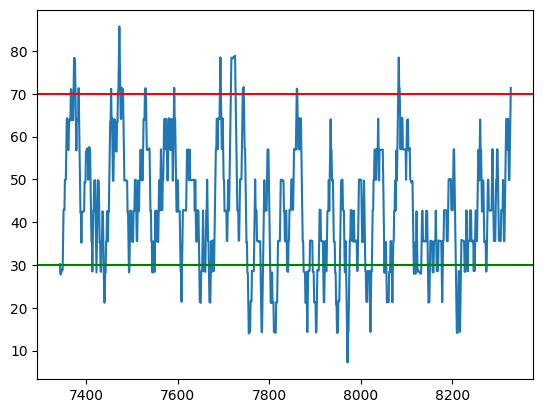

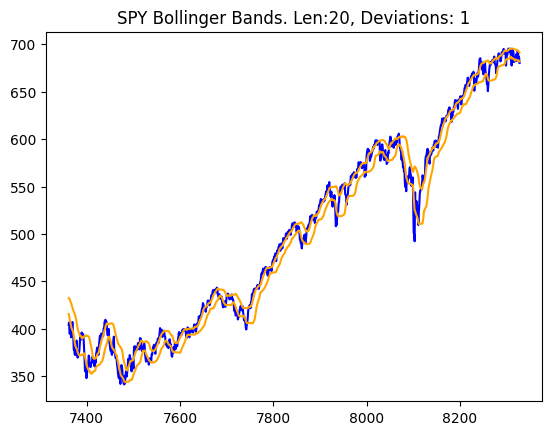

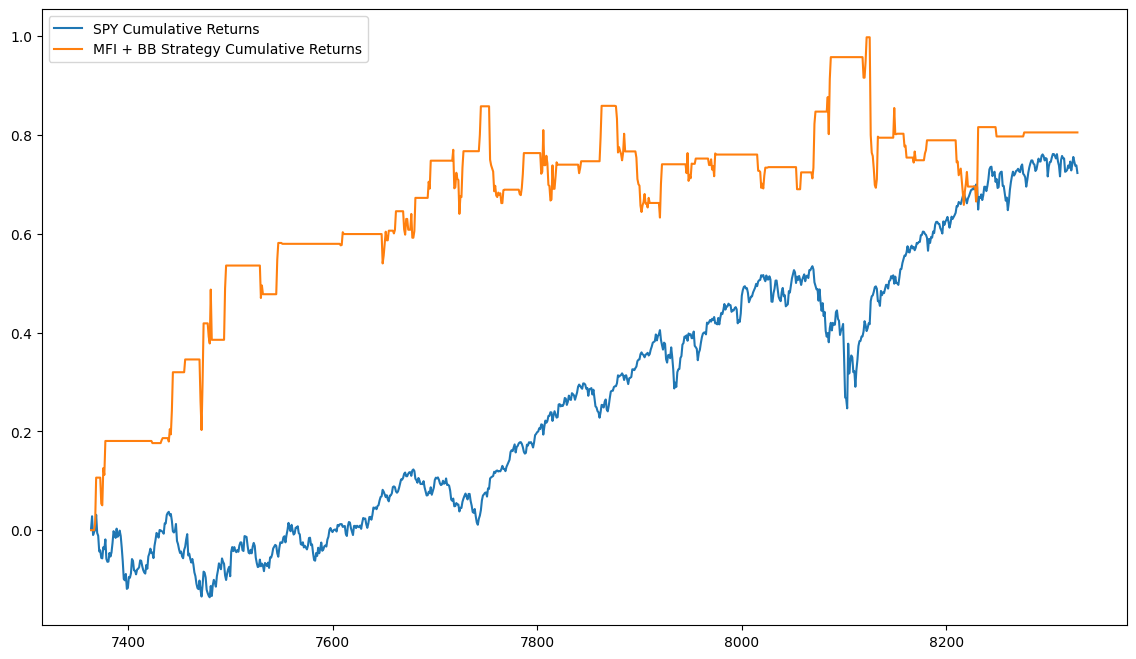

In [3]:
TICKER = 'SPY'
PERIOD = 'max'
INTERVAL = '1d'

#set period based on interval
if INTERVAL == '1h':
    PERIOD = '730d'
else:
    PERIOD = 'max'

#BB variables
BB_LEN = 20
DEVS = 1

#MFI variables
MFI_LENGTH = 14
MFI_OVERBOUGHT = 70 
MFI_OVERSOLD = 30  


#what subsection of the data you are interested in
LOOKBACK = 1000


def get_data(ticker=TICKER, start=start, end=end, lookback=LOOKBACK, interval=INTERVAL):

    #get data at preferred interval
    df = yf.download(ticker, interval=interval, period=PERIOD)
    df.columns = df.columns.get_level_values(0)

    #reset index to make the plots look better; removes times when stock market isn't active
    df = df.reset_index(drop=True)

    return df.iloc[-lookback:, :]


def add_MFI(df, length=MFI_LENGTH):

    df['Average_Price'] = (df['High'] + df['Low'] + df['Close']) / 3
    df['Money_Flow'] = df['Volume'] * df['Average_Price']

    df['Pos_Flow'] = 0
    df['Neg_Flow'] = 0

    df['Pos_Flow'] = np.where(df['Average_Price'].diff() > 0, df['Average_Price'], 0)
    df['Neg_Flow'] = np.where(df['Average_Price'].diff() < 0, df['Average_Price'], 0)

    mfr = df['Pos_Flow'].rolling(length).sum() / df['Neg_Flow'].rolling(length).sum()

    #add money flow column
    df['MFI'] = (100 / (1 + mfr))

    plt.figure()
    plt.plot(df['MFI'])
    plt.axhline(MFI_OVERBOUGHT, color='red')
    plt.axhline(MFI_OVERSOLD, color='green')

    return df.dropna()

def add_MFI_strategy(df, overbought=MFI_OVERBOUGHT, oversold=MFI_OVERSOLD):

    df['MFI_Strategy'] = 0
    df['MFI_Strategy'] = np.where(df['MFI'] > overbought, 1,
                              np.where(df['MFI'] < oversold, -1, 0))
    #shift back to make sure we don't inflate results
    df['MFI_Strategy'] = df['MFI_Strategy'].shift(1)
    return df.dropna()


def add_BB(df, devs=DEVS, bb_len=BB_LEN):
    
    #Can change to ema instead of ma; just change .rolling to .ewm
    df['BB_SMA'] = df['Close'].rolling(bb_len).mean()

    #this is just to show the value in the df, don't add a whole column for a value
    df['BB_STD'] = df['Close'].rolling(bb_len).std()

    df['Upper_Band'] = df['BB_SMA'] + (devs * df['BB_STD'])
    df['Lower_Band'] = df['BB_SMA'] - (devs * df['BB_STD'])

    df = df.dropna()

    plt.figure()
    plt.plot(df['Close'], color='blue')
    plt.plot(df['Upper_Band'], color='orange')
    plt.plot(df['Lower_Band'], color='orange')

    plt.title(f'{TICKER} Bollinger Bands. Len:{BB_LEN}, Deviations: {DEVS}')

    return df.dropna()

def add_BB_strategy(df):

    df['BB_Strategy'] = 0
    df['BB_Strategy'] = np.where(
        df['Close'] > df['Upper_Band'], -1,
        np.where(df['Close'] < df['Lower_Band'], 1, 0))
    
    #shift back to make sure we don't inflate results
    df['BB_Strategy'] = df['BB_Strategy'].shift(1)
    return df.dropna()


def add_full_strategy(df):

    df['Full_Strategy'] = df['MFI_Strategy'] + df['BB_Strategy']

    #adjust values for simplicity

    df['Strategy'] = np.where(
        df['Full_Strategy'] == 2, 3, #normally you would keep at 1, but if the strategy is not too shit then u can change increase it to smth like 3, meaning you triple leverage the strategy (take advantage of it and put thrice the amount of money at stake) and see if u could beat the SPY 
        np.where(df['Full_Strategy'] == -2, -3, 0)
        )
    
    return df


def test_strategy(df):

    df['Asset_Returns'] = (1 + df['Close'].pct_change()).cumprod() - 1
    df['Strategy_Returns'] = (1 + df['Close'].pct_change() * df['Strategy'].shift()).cumprod() - 1

    plt.figure(figsize=(14, 8))
    plt.plot(df['Asset_Returns'], label='Asset Returns')
    plt.plot(df['Strategy_Returns'], label='Strategy Returns')
    plt.legend([f'{TICKER} Cumulative Returns', f'MFI + BB Strategy Cumulative Returns'])
    return df


def main():

    df = get_data()
    df = add_MFI(df)
    df = add_BB(df)

    df = add_MFI_strategy(df)
    df = add_BB_strategy(df)

    df = add_full_strategy(df)
    df = test_strategy(df)

    return df


df = main()
df

#this Strategy beats the SPY over 1000 days with leverage and beats it over 100 days even without leverage
#Could be promising